# 09 · PINN twin in 2D: reconstruct, identify, forecast
**Level: Expert** · ~25 min (training ≈ 6-8 min on CPU) · *Track: Scientific ML*

A puff of contaminant is released into a flowing channel. A 6×6 array of probes records it.
Nothing else is known: not the release point, not the initial size, not the flow velocity, not
the diffusivity. The PINN twin must:

1. **reconstruct** the full space-time field $c(x,y,t)$ between the probes,
2. **identify** the physics: diffusivity $\kappa$ and velocity $(v_x, v_y)$,
3. **forecast** beyond the last measurement, where only the PDE constrains the network.

$$c_t + v_x c_x + v_y c_y = \kappa\,(c_{xx}+c_{yy})$$

Notice what is *missing* compared to notebook 08: no initial condition and no boundary conditions.
Sensors + PDE are enough, which makes PINNs attractive for twins whose initial state is unknown.

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.interpolate import griddata
from IPython.display import HTML
from dtwin import viz
from dtwin.pinn import MLP, grad, tensor, train, set_seed
viz.set_style()
set_seed(0)
rng = np.random.default_rng(0)

## 1. Reality: an advected, diffusing Gaussian puff (exact solution)

936 noisy readings from 36 probes


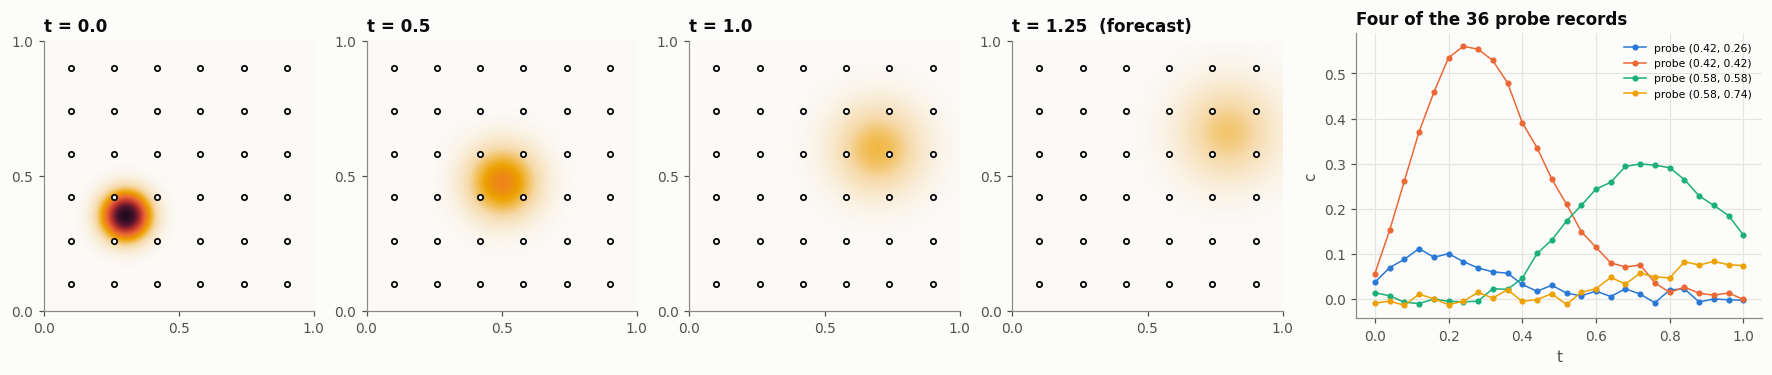

In [2]:
KAPPA, VX, VY = 0.005, 0.4, 0.25
X0, Y0, S0 = 0.3, 0.35, 0.06
T_DATA, T_FORECAST = 1.0, 1.3

def puff(x, y, t):
    s2 = S0**2 + 2 * KAPPA * t
    return S0**2 / s2 * np.exp(-((x - X0 - VX * t) ** 2 + (y - Y0 - VY * t) ** 2) / (2 * s2))

ng = 80
xg = np.linspace(0, 1, ng)
XX, YY = np.meshgrid(xg, xg)
tg = np.linspace(0, T_FORECAST, 40)
C_true = np.array([puff(XX, YY, t) for t in tg])

k_sens = 6
sp = np.linspace(0.1, 0.9, k_sens)
SXg, SYg = np.meshgrid(sp, sp)
sx, sy = SXg.ravel(), SYg.ravel()
st = np.linspace(0, T_DATA, 26)
Y_clean = np.array([puff(sx, sy, t) for t in st])          # (26, 36)
Y_noisy = Y_clean + 0.01 * rng.standard_normal(Y_clean.shape)
print(f"{Y_noisy.size} noisy readings from {sx.size} probes")

show_t = [0.0, 0.5, 1.0, 1.25]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.3), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
for ax, tt in zip(axes[:4], show_t):
    viz.field(ax, puff(XX, YY, tt), vmin=0, vmax=1, cbar=False,
              title=f"t = {tt}" + ("  (forecast)" if tt > T_DATA else ""))
    viz.sensors_2d(ax, sx, sy, s=12)
ax = axes[4]
for i, j in enumerate([8, 14, 21, 27]):
    ax.plot(st, Y_noisy[:, j], "o-", ms=3, lw=1, color=viz.SERIES[i], label=f"probe ({sx[j]:.2f}, {sy[j]:.2f})")
ax.set(xlabel="t", ylabel="c", title="Four of the 36 probe records")
ax.legend(fontsize=7)
plt.show()

## 2. The PINN twin
* Input $(x, y, t)$ → output $c$; 4 hidden layers × 48 tanh units, 6,000 collocation points.
* Unknowns: network weights + $\log\kappa$, $v_x$, $v_y$, initialised to κ = 0.02 and **no flow**.
* Collocation points cover $t\in[0, 1.3]$; data only cover $t\le1$. On $(1, 1.3]$ the PDE alone
  drives the solution, which is the forecast.
* Loss weights: data 20, PDE 1. Too much data weight lets the network fit the probes while ignoring
  the PDE, and then κ (which only the PDE term "sees") learns very slowly.

In [3]:
Xc = tensor(np.c_[rng.uniform(0, 1, 6000), rng.uniform(0, 1, 6000), rng.uniform(0, T_FORECAST, 6000)],
            requires_grad=True)
STT, SI = np.meshgrid(st, np.arange(sx.size), indexing="ij")
Xd = tensor(np.c_[sx[SI.ravel()], sy[SI.ravel()], STT.ravel()])
Yd = tensor(Y_noisy.ravel()[:, None])

net = MLP(3, 1, width=48, depth=4, lb=[0, 0, 0], ub=[1, 1, T_FORECAST])
log_k = torch.nn.Parameter(torch.tensor(np.log(0.02), dtype=torch.float32))
vx = torch.nn.Parameter(torch.tensor(0.0))
vy = torch.nn.Parameter(torch.tensor(0.0))

def pde_residual(X):
    c = net(X)
    d = grad(c, X)
    cx, cy, ct = d[:, :1], d[:, 1:2], d[:, 2:]
    cxx = grad(cx, X)[:, :1]
    cyy = grad(cy, X)[:, 1:2]
    return ct + vx * cx + vy * cy - torch.exp(log_k) * (cxx + cyy)

def loss_fn():
    lr = (pde_residual(Xc) ** 2).mean()
    ld = ((net(Xd) - Yd) ** 2).mean()
    return lr + 20 * ld, {"pde": lr.item(), "data": ld.item(), "kappa": torch.exp(log_k).item(),
                           "vx": vx.item(), "vy": vy.item()}

groups = [{"params": list(net.parameters())}, {"params": [log_k, vx, vy], "lr": 1e-2}]
t0 = time.time()
hist = train(loss_fn, groups, n_adam=4000, lr=2e-3, n_lbfgs=2000, log_every=1000)
print(f"trained in {time.time() - t0:.0f}s")

adam     0  loss 1.040e+00  pde 1.42e-01  data 4.49e-02  kappa 2.00e-02  vx 0.00e+00  vy 0.00e+00  (0s)


adam  1000  loss 4.088e-03  pde 5.34e-04  data 1.78e-04  kappa 1.47e-03  vx 4.04e-01  vy 2.15e-01  (116s)


adam  2000  loss 3.247e-03  pde 5.25e-04  data 1.36e-04  kappa 1.94e-03  vx 4.05e-01  vy 2.25e-01  (156s)


adam  3000  loss 2.873e-03  pde 4.68e-04  data 1.20e-04  kappa 2.16e-03  vx 4.06e-01  vy 2.32e-01  (181s)


adam  3999  loss 2.641e-03  pde 4.22e-04  data 1.11e-04  kappa 2.26e-03  vx 4.07e-01  vy 2.35e-01  (209s)


lbfgs done  loss 1.661e-03  (266s)
trained in 267s


kappa  estimated 0.0041   true 0.0050   error 17.9%
vx     estimated 0.4061   true 0.4000   error 1.5%
vy     estimated 0.2514   true 0.2500   error 0.6%


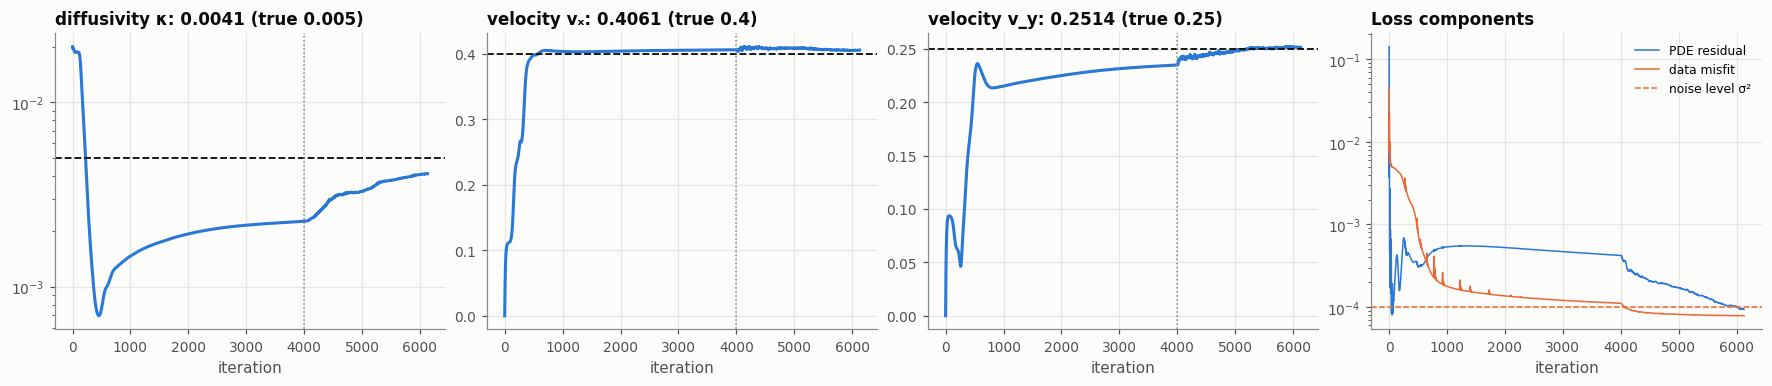

In [4]:
est = {"kappa": hist["kappa"][-1], "vx": hist["vx"][-1], "vy": hist["vy"][-1]}
truth = {"kappa": KAPPA, "vx": VX, "vy": VY}
for k in est:
    print(f"{k:6s} estimated {est[k]:.4f}   true {truth[k]:.4f}   error {abs(est[k]/truth[k]-1)*100:.1f}%")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), constrained_layout=True)
n_adam = hist["phase"].count("adam")
for ax, k, lbl in zip(axes[:3], ["kappa", "vx", "vy"], ["diffusivity κ", "velocity vₓ", "velocity v_y"]):
    ax.plot(hist[k], color=viz.TWIN)
    ax.axhline(truth[k], color=viz.TRUTH, ls="--", lw=1.2)
    ax.axvline(n_adam, color=viz.MUTED, ls=":", lw=1)
    ax.set(xlabel="iteration", title=f"{lbl}: {est[k]:.4f} (true {truth[k]})")
axes[0].set_yscale("log")
axes[3].semilogy(hist["pde"], color=viz.SERIES[0], lw=1, label="PDE residual")
axes[3].semilogy(hist["data"], color=viz.SERIES[1], lw=1, label="data misfit")
axes[3].axhline(0.01**2, color=viz.DATA, ls="--", lw=1, label="noise level σ²")
axes[3].set(xlabel="iteration", title="Loss components")
axes[3].legend(fontsize=8)
plt.show()

The data misfit settles near the **noise level** σ² = 10⁻⁴ (dashed): the twin fits the signal,
not the noise. Going lower would mean over-fitting.

**Why is κ the least accurate?** The velocities move the puff's *centre*, which 36 probes track
easily (first-order effect). κ only changes the puff's *width* (σ² grows from 0.0036 to 0.0136
over the record), a second-order effect sampled by probes 0.16 apart and partly confounded with
the unknown initial size. Expect ~10-20% on κ and ~1-2% on velocities: the same identifiability
lesson as notebooks 03 and 08.

## 3. Physics vs. interpolation: reconstruction and forecast
Baseline: cubic interpolation of the 36 probes at each time (data only, no physics). It cannot
forecast at all, so we hold its last frame for $t>1$ (persistence).

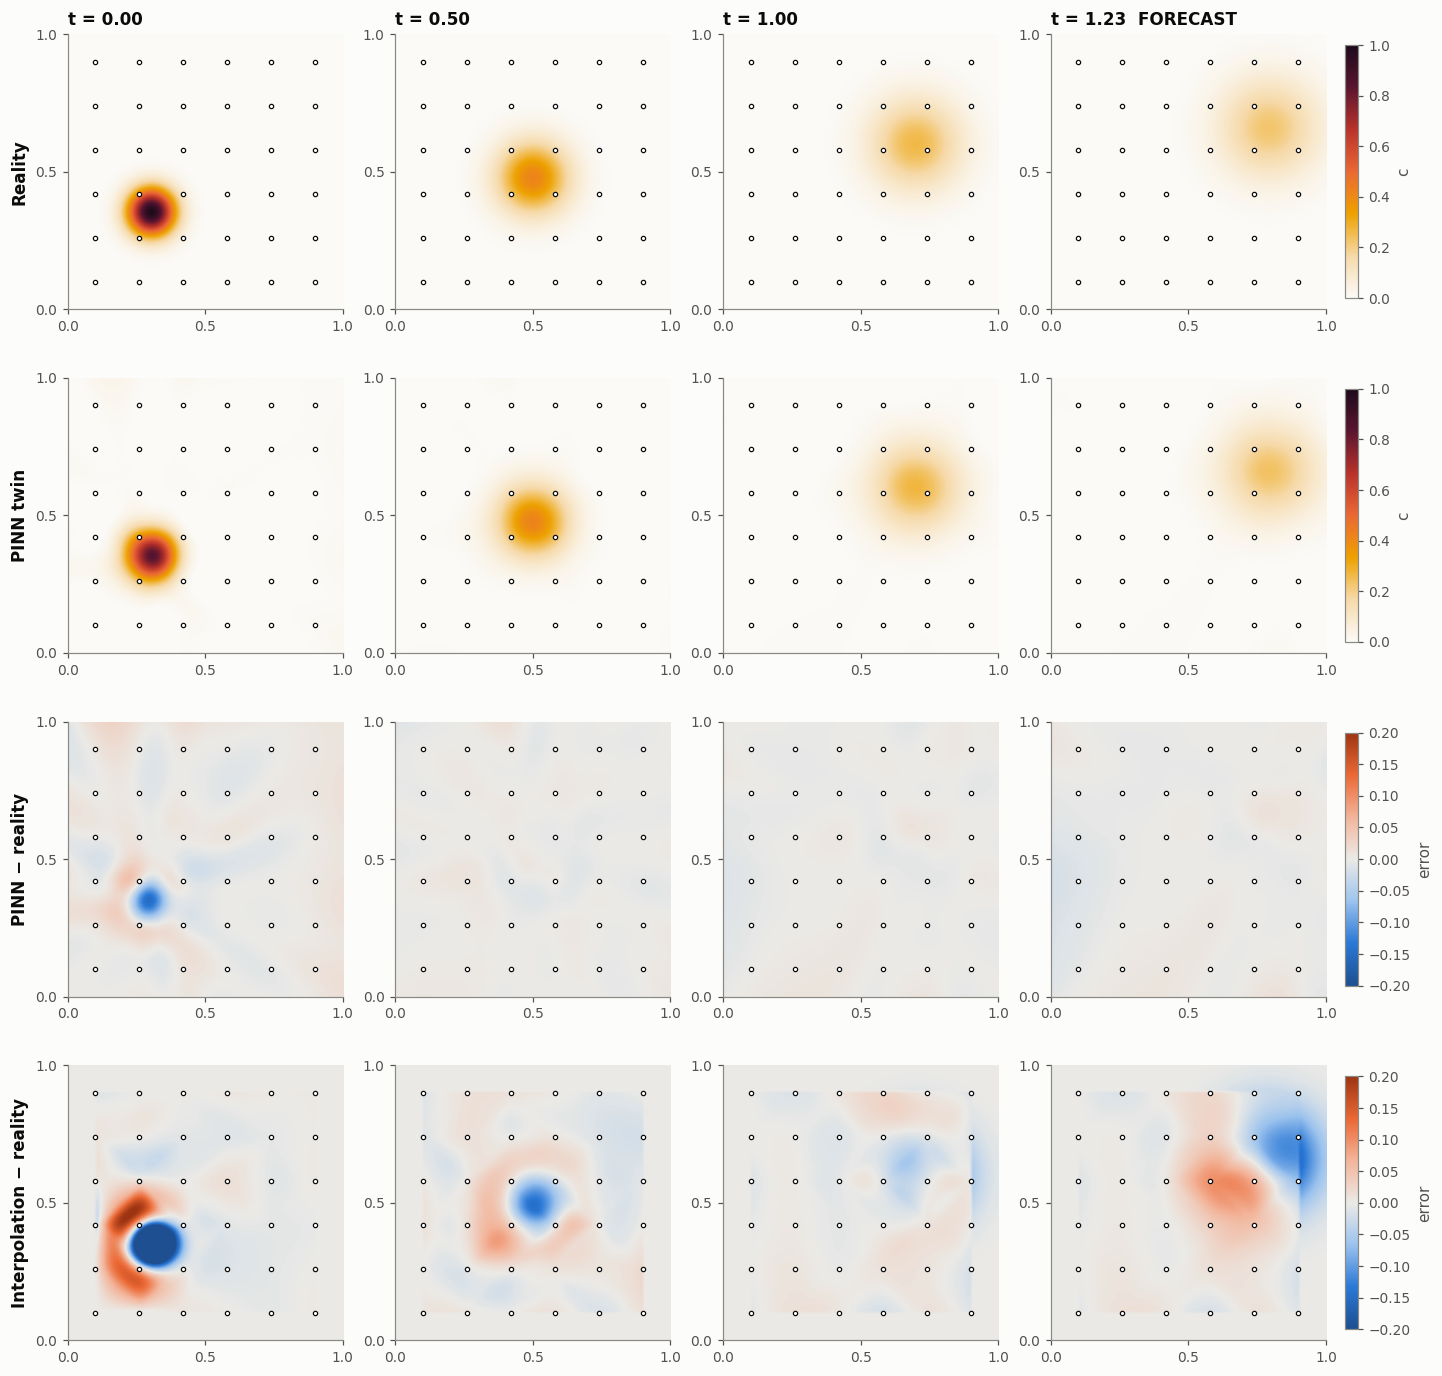

In [5]:
def pinn_field(t):
    pts = tensor(np.c_[XX.ravel(), YY.ravel(), np.full(XX.size, t)])
    with torch.no_grad():
        return net(pts).numpy().reshape(XX.shape)

def interp_field(t):
    j = np.argmin(abs(st - min(t, T_DATA)))
    return griddata((sx, sy), Y_noisy[j], (XX, YY), method="cubic", fill_value=0.0)

C_pinn = np.array([pinn_field(t) for t in tg])
C_intp = np.array([interp_field(t) for t in tg])

fig, axes = plt.subplots(4, 4, figsize=(13, 12.5), constrained_layout=True)
for j, tt in enumerate(show_t):
    k = np.argmin(abs(tg - tt))
    tag = f"t = {tg[k]:.2f}" + ("  FORECAST" if tg[k] > T_DATA else "")
    viz.field(axes[0, j], C_true[k], vmin=0, vmax=1, cbar=j == 3, label="c", title=tag)
    viz.field(axes[1, j], C_pinn[k], vmin=0, vmax=1, cbar=j == 3, label="c")
    viz.field(axes[2, j], C_pinn[k] - C_true[k], cmap=viz.DIVERGING, vmin=-0.2, vmax=0.2, cbar=j == 3, label="error")
    viz.field(axes[3, j], C_intp[k] - C_true[k], cmap=viz.DIVERGING, vmin=-0.2, vmax=0.2, cbar=j == 3, label="error")
    for r in range(4):
        viz.sensors_2d(axes[r, j], sx, sy, s=8, linewidth=0.8)
for r, name in enumerate(["Reality", "PINN twin", "PINN − reality", "Interpolation − reality"]):
    axes[r, 0].set_ylabel(name, fontsize=11, color=viz.INK, fontweight="semibold")
viz.save(fig, "09_pinn_2d.png")
plt.show()

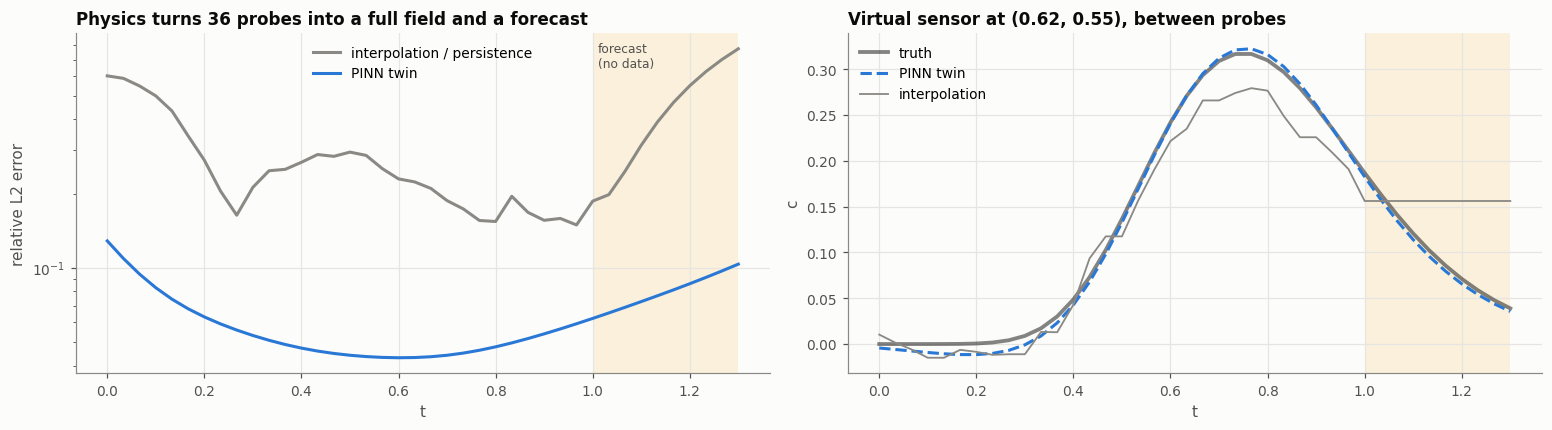

In [6]:
rel = lambda A: np.linalg.norm((A - C_true).reshape(len(tg), -1), axis=1) / np.linalg.norm(C_true.reshape(len(tg), -1), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
ax = axes[0]
ax.axvspan(T_DATA, T_FORECAST, color=viz.YELLOW, alpha=0.12, lw=0)
ax.text(T_DATA + 0.01, 0.9, "forecast\n(no data)", transform=ax.get_xaxis_transform(), fontsize=8, color=viz.INK2)
ax.semilogy(tg, rel(C_intp), color=viz.MUTED, label="interpolation / persistence")
ax.semilogy(tg, rel(C_pinn), color=viz.TWIN, label="PINN twin")
ax.set(xlabel="t", ylabel="relative L2 error", title="Physics turns 36 probes into a full field and a forecast")
ax.legend()
ax = axes[1]
vp = (0.62, 0.55)                                  # a virtual sensor between probes
iv = (np.argmin(abs(xg - vp[1])), np.argmin(abs(xg - vp[0])))
ax.axvspan(T_DATA, T_FORECAST, color=viz.YELLOW, alpha=0.12, lw=0)
ax.plot(tg, C_true[:, iv[0], iv[1]], color=viz.TRUTH, lw=2.5, alpha=0.5, label="truth")
ax.plot(tg, C_pinn[:, iv[0], iv[1]], "--", color=viz.TWIN, label="PINN twin")
ax.plot(tg, C_intp[:, iv[0], iv[1]], color=viz.MUTED, lw=1.2, label="interpolation")
ax.set(xlabel="t", ylabel="c", title=f"Virtual sensor at ({vp[0]}, {vp[1]}), between probes")
ax.legend()
plt.show()

In [7]:
anim = viz.animate_2d([C_true, C_pinn, C_pinn - C_true], tg, ["Reality", "PINN twin", "Twin − reality"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.DIVERGING], vlims=[(0, 1), (0, 1), (-0.15, 0.15)],
                      sensors=(sx, sy), size=3.3, interval=150)
HTML(anim.to_jshtml())

## 4. Where did the puff come from? Back-tracking the source
The twin's field at $t=0$ is an estimate of the **release**, even though no probe was near it.
This works because advection-diffusion is (mildly) invertible backwards for short times. It
would degrade quickly for longer horizons, since diffusion destroys information.

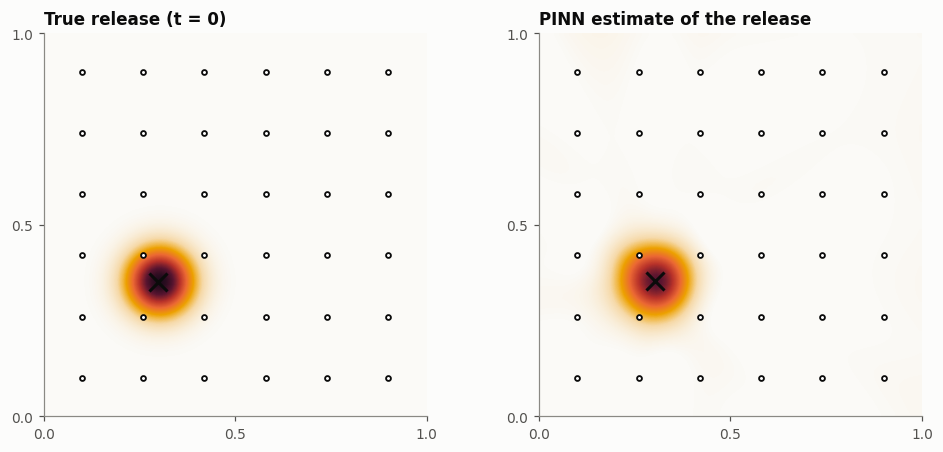

estimated release point (0.304, 0.354), true (0.3, 0.35)


In [8]:
c0_hat = C_pinn[0]
iy, ix = np.unravel_index(np.argmax(c0_hat), c0_hat.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
viz.field(axes[0], C_true[0], vmin=0, vmax=1, cbar=False, title="True release (t = 0)")
viz.field(axes[1], c0_hat, vmin=0, vmax=1, cbar=False, title="PINN estimate of the release")
for ax in axes:
    viz.sensors_2d(ax, sx, sy, s=10)
axes[1].plot(xg[ix], xg[iy], "x", color=viz.INK, ms=12, mew=2)
axes[0].plot(X0, Y0, "x", color=viz.INK, ms=12, mew=2)
plt.show()
print(f"estimated release point ({xg[ix]:.3f}, {xg[iy]:.3f}), true ({X0}, {Y0})")

## Recap and expert remarks
* One loss function performs **state reconstruction, parameter identification and forecasting**.
* No initial or boundary conditions were needed: data + PDE regularise each other.
* Fit to the noise level, not below it. Use the noise floor to choose loss weights.
* **Limits:** training takes minutes (not milliseconds); there are no native error bars (use deep
  ensembles or Bayesian PINNs); long forecasts drift once data stop constraining the network; and
  strongly multiscale or turbulent fields remain hard.
* In operational twins, PINNs often serve as **offline calibrators or surrogates**, while fast filters
  (06-07) do the real-time tracking. The capstone (10) combines exactly these pieces.

**Exercises**
1. Use 3×3 probes. Which parameter degrades first?
2. Extend the forecast window to $t=2$. Where does the error grow, and why?
3. Train 5 PINNs with different seeds (a deep ensemble) and map the standard deviation of the field.